NAT_LB_NOM
Pylône autostable            44.8
Bâtiment                     15.9
Immeuble                     14.3
Pylône tubulaire              9.3
Château d'eau - réservoir     3.9
Mât                           1.8
Mât métallique                1.4
Monument religieux            1.1
Tunnel                        1.1
Mât béton                     1.0
Name: count, dtype: float64


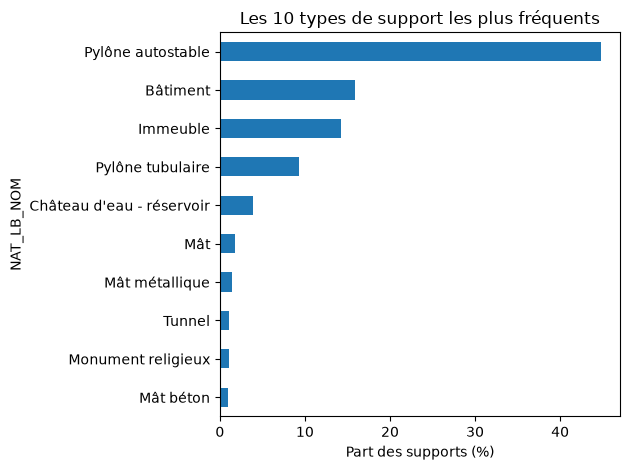

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

# ÉTAPE 1 : charger les deux fichiers dont on a besoin
support = pd.read_csv(dossier + "sup_support.txt", sep=";", dtype=str, encoding="utf-8")
nature = pd.read_csv(dossier1 + "sup_nature.txt", sep=";", dtype=str, encoding="utf-8")

# ÉTAPE 2 : garder une seule ligne par support
support = support.drop_duplicates(subset="SUP_ID")

# ÉTAPE 3 : remplacer le numéro de nature par son nom
support = support.merge(nature, on="NAT_ID", how="left")

# ÉTAPE 4 : compter chaque type de support
classement = support["NAT_LB_NOM"].value_counts().head(10)

# ÉTAPE 5 : calculer le pourcentage
pourcentage = (classement / len(support) * 100).round(1)
print(pourcentage)

# ÉTAPE 6 : faire le graphique
pourcentage.sort_values().plot(kind="barh")
plt.xlabel("Part des supports (%)")
plt.title("Les 10 types de support les plus fréquents")
plt.tight_layout()
plt.savefig("q1_natures.png")

In [16]:
import pandas as pd
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor
from pptx.enum.shapes import MSO_SHAPE
from pptx.enum.text import PP_ALIGN

dossier = "/Users/coupr/OneDrive/Desktop/SAE15/data/data/"
dossier1 = "/Users/coupr/OneDrive/Desktop/SAE15/ref/ref/"

# ============ PARTIE 1 : les calculs ============
support = pd.read_csv(dossier + "sup_support.txt", sep=";", dtype=str, encoding="utf-8")
nature = pd.read_csv(dossier1 + "sup_nature.txt", sep=";", dtype=str, encoding="utf-8")

support = support.drop_duplicates(subset="SUP_ID")
support = support.merge(nature, on="NAT_ID", how="left")
total = len(support)

top5 = (support["NAT_LB_NOM"].value_counts().head(5) / total * 100).round(1)

pylones = support["NAT_LB_NOM"].str.contains("ylône").mean() * 100
autostables = (support["NAT_LB_NOM"] == "Pylône autostable").mean() * 100
batiments = support["NAT_LB_NOM"].isin(["Bâtiment", "Immeuble"]).mean() * 100

# ============ PARTIE 2 : la diapo ============
FOND = RGBColor(0xF6, 0xF3, 0xEC)
BLEU = RGBColor(0x14, 0x21, 0x3D)
GRIS = RGBColor(0x3D, 0x4A, 0x63)
ORANGE = RGBColor(0xE0, 0x56, 0x1F)
CARTE = RGBColor(0xFF, 0xFD, 0xF8)
PISTE = RGBColor(0xE9, 0xE4, 0xD8)


def ajouter_texte(diapo, x, y, largeur, hauteur, morceaux, taille, couleur=BLEU,
                  gras=False, alignement=PP_ALIGN.LEFT):
    """Écrit un texte. 'morceaux' = liste de (texte, couleur, gras)."""
    boite = diapo.shapes.add_textbox(Inches(x), Inches(y), Inches(largeur), Inches(hauteur))
    cadre = boite.text_frame
    cadre.word_wrap = True
    paragraphe = cadre.paragraphs[0]
    paragraphe.alignment = alignement
    for texte, c, g in morceaux:
        run = paragraphe.add_run()
        run.text = texte
        run.font.size = Pt(taille)
        run.font.name = "Calibri"
        run.font.color.rgb = c or couleur
        run.font.bold = g if g is not None else gras
    return boite


def ajouter_rectangle(diapo, forme, x, y, largeur, hauteur, couleur):
    r = diapo.shapes.add_shape(forme, Inches(x), Inches(y), Inches(largeur), Inches(hauteur))
    r.fill.solid()
    r.fill.fore_color.rgb = couleur
    r.line.fill.background()   # pas de contour
    return r


prs = Presentation()
prs.slide_width = Inches(13.333)    # format 16:9
prs.slide_height = Inches(7.5)
diapo = prs.slides.add_slide(prs.slide_layouts[6])   # diapo vide
diapo.background.fill.solid()
diapo.background.fill.fore_color.rgb = FOND

# --- colonne de gauche : la question et la réponse ---
ajouter_texte(diapo, 0.9, 1.3, 4.5, 0.5, [("Question 1", ORANGE, True)], 20)
ajouter_texte(diapo, 0.9, 1.9, 4.6, 2.6, [("Quels types de support dominent ?", BLEU, True)], 40)
ajouter_texte(diapo, 0.9, 4.3, 4.5, 2.2, [
    (f"{pylones:.0f}\u00a0%", ORANGE, True),
    (" des supports d'antennes sont des pylônes, dont ", GRIS, False),
    (f"{autostables:.0f}\u00a0%", ORANGE, True),
    (" de pylônes autostables. Les bâtiments et immeubles arrivent ensuite avec ", GRIS, False),
    (f"{batiments:.0f}\u00a0%", ORANGE, True),
    (".", GRIS, False),
], 20)

# --- colonne de droite : la carte avec le top 5 ---
X0, LARGEUR = 5.9, 6.5
ajouter_rectangle(diapo, MSO_SHAPE.ROUNDED_RECTANGLE, X0, 0.9, LARGEUR, 5.6, CARTE).adjustments[0] = 0.05
ajouter_texte(diapo, X0 + 0.4, 1.1, 5.5, 0.4, [("Top 5 des types de support", GRIS, True)], 16)

pct_max = top5.max()
for i, (nom, pct) in enumerate(top5.items()):
    y = 1.75 + i * 0.93
    ajouter_texte(diapo, X0 + 0.4, y, 4.5, 0.4, [(f"{i + 1}. {nom}", BLEU, True)], 18)
    ajouter_texte(diapo, X0 + LARGEUR - 1.8, y, 1.4, 0.4,
                  [(f"{pct:.1f}\u00a0%".replace(".", ","), BLEU, True)], 18, alignement=PP_ALIGN.RIGHT)
    largeur_piste = LARGEUR - 0.8
    ajouter_rectangle(diapo, MSO_SHAPE.ROUNDED_RECTANGLE, X0 + 0.4, y + 0.5, largeur_piste, 0.14, PISTE)
    couleur_barre = ORANGE if i == 0 else BLEU
    ajouter_rectangle(diapo, MSO_SHAPE.ROUNDED_RECTANGLE, X0 + 0.4, y + 0.5,
                      largeur_piste * pct / pct_max, 0.14, couleur_barre)

ajouter_texte(diapo, 0.9, 6.85, 11, 0.4,
              [(f"Source : ANFR · {total:,} supports distincts".replace(",", " "), GRIS, False)], 12)

prs.save("diapo_q1.pptx")
print("Diapo enregistrée : diapo_q1.pptx")

Diapo enregistrée : diapo_q1.pptx


In [15]:
import sys
!{sys.executable} -m pip install --user python-pptx

   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/4.0 MB ? eta -:--:--
   -------------------------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\coupr\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip
